# Spam Email Classifier
Train and compare Naive Bayes and Support Vector Machine (SVM) models to detect spam emails based on their content.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import urllib.request
import zipfile
import os

print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Load and Explore Dataset
We will use a standard public SMS/Email spam dataset hosted on GitHub for ease of access.

In [2]:
# Download the dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])

# Map labels to binary values for compatibility
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print(f"Dataset shape: {df.shape}")
display(df.head())

# Check class distribution
print("\nClass counts:")
print(df['label'].value_counts())

Dataset shape: (5572, 3)


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0



Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64


## 2. Train-Test Split and Feature Extraction
We will split the dataset into training and test sets and use **TF-IDF Vectorization** to convert textual message data into numeric vectors.

In [3]:
X = df['message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Extract features using TF-IDF vectorization
vectorizer = TfidfVectorizer(stop_words='english', lowercase=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Training feature shape: {X_train_tfidf.shape}")
print(f"Testing feature shape: {X_test_tfidf.shape}")

Training feature shape: (4457, 7403)
Testing feature shape: (1115, 7403)


## 3. Model Training & Evaluation
We will train both **Naive Bayes (MultinomialNB)** and **Support Vector Machine (SVC)** models, then display the performance classification reports.

In [4]:
# 1. Naive Bayes Classifier
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

# 2. Support Vector Machine Classifier
svm_model = SVC(kernel='linear', C=1.0, random_state=42)
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)

# Evaluate and compare accuracy
print(f"Naive Bayes Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")

Naive Bayes Accuracy: 0.9704
SVM Accuracy: 0.9839


### Detailed Performance Reports
Let's plot confusion matrices for both classifiers.

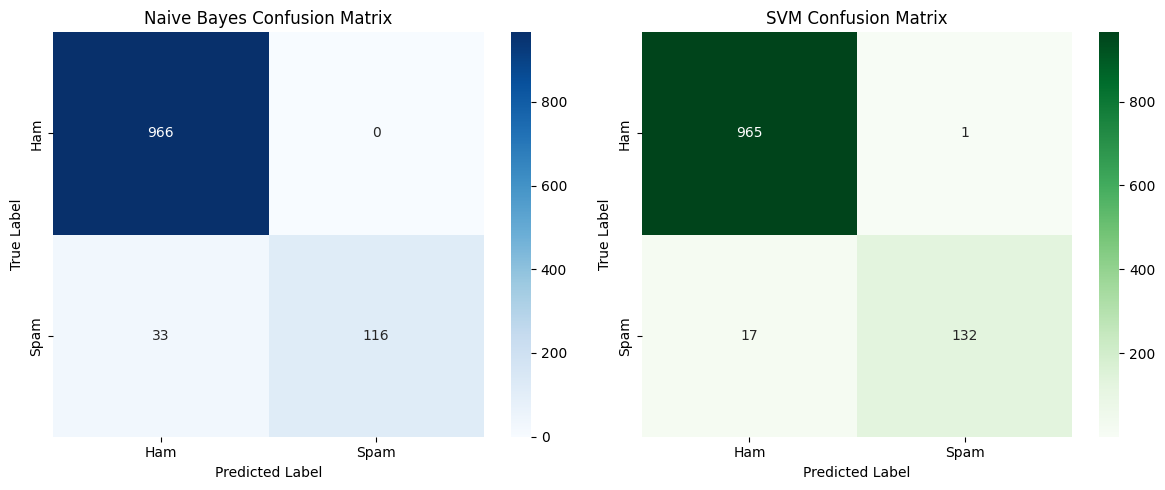

--- Naive Bayes Classification Report ---
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115


--- Support Vector Machine Classification Report ---
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.99      0.89      0.94       149

    accuracy                           0.98      1115
   macro avg       0.99      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Naive Bayes Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'], ax=axes[0])
axes[0].set_title('Naive Bayes Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# SVM Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Greens',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'], ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

print("--- Naive Bayes Classification Report ---")
print(classification_report(y_test, y_pred_nb, target_names=['Ham', 'Spam']))

print("\n--- Support Vector Machine Classification Report ---")
print(classification_report(y_test, y_pred_svm, target_names=['Ham', 'Spam']))

## 4. Test on Custom Messages
You can test custom emails or messages below to check if they are classified as Spam or Ham.

In [16]:
custom_messages = [
    "Congratulations! You have won a free ticket to the Bahamas. Text claim to 80802 to win now!",
    "Hey, are we still meeting for lunch today? Let me know.",
    "URGENT: Your account access has been suspended. Please click on this link to verify your identity immediately."
]

# Re-create the specific vectorizer used to train nb_model and svm_model to guarantee 7403 features
baseline_vectorizer = TfidfVectorizer(stop_words='english', lowercase=True)
baseline_vectorizer.fit(X_train)

# Transform the custom messages
custom_features = baseline_vectorizer.transform(custom_messages)

# Predict using the baseline models
nb_predictions = nb_model.predict(custom_features)
svm_predictions = svm_model.predict(custom_features)

for i, msg in enumerate(custom_messages):
    print(f"Message: {msg}")
    print(f"-> Naive Bayes Prediction: {'SPAM' if nb_predictions[i] == 1 else 'HAM'}")
    print(f"-> SVM Prediction: {'SPAM' if svm_predictions[i] == 1 else 'HAM'}")
    print("-" * 50)

Message: Congratulations! You have won a free ticket to the Bahamas. Text claim to 80802 to win now!
-> Naive Bayes Prediction: SPAM
-> SVM Prediction: SPAM
--------------------------------------------------
Message: Hey, are we still meeting for lunch today? Let me know.
-> Naive Bayes Prediction: HAM
-> SVM Prediction: HAM
--------------------------------------------------
Message: URGENT: Your account access has been suspended. Please click on this link to verify your identity immediately.
-> Naive Bayes Prediction: SPAM
-> SVM Prediction: SPAM
--------------------------------------------------


In [8]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 20.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 35.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [9]:
import streamlit as st
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC

# Set page configuration
st.set_page_config(page_title="Spam Email Classifier", page_icon="✉️", layout="centered")

# Title and description
st.title("✉️ Spam Email Classifier")
st.write("This application uses Machine Learning to classify incoming emails or messages as **Spam** or **Ham (Legitimate)**.")

@st.cache_resource
def load_classifier_and_vectorizer():
    # Fetch and prepare dataset dynamically for demo purposes
    url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
    df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])
    df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

    vectorizer = TfidfVectorizer(stop_words='english', lowercase=True)
    X = vectorizer.fit_transform(df['message'])
    y = df['label_num']

    # Train SVM (best performer)
    svm_model = SVC(kernel='linear', C=1.0, probability=True)
    svm_model.fit(X, y)
    return vectorizer, svm_model

try:
    vectorizer, model = load_classifier_and_vectorizer()
    st.success("Model loaded successfully!")
except Exception as e:
    st.error(f"Error loading the classifier: {e}")

# User input
user_input = st.text_area("Paste the email or message content below:", height=150,
                          placeholder="Enter your message here...")

if st.button("Classify Message", type="primary"):
    if user_input.strip() == "":
        st.warning("Please enter some text to classify.")
    else:
        # Vectorize input
        transformed_input = vectorizer.transform([user_input])

        # Predict
        prediction = model.predict(transformed_input)[0]
        probabilities = model.predict_proba(transformed_input)[0]

        # Display Results
        st.markdown("--- ")
        if prediction == 1:
            st.error(f"🚨 **Result: SPAM** (Confidence: {probabilities[1]*100:.2f}%)")
        else:
            st.success(f"✅ **Result: HAM** (Confidence: {probabilities[0]*100:.2f}%)")

2026-11-02 11:36:00.704 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-02 11:36:00.707 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-02 11:36:01.195 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-02 11:36:01.196 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-02 11:36:01.200 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-02 11:36:01.201 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-02 11:36:01.204 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

## 6. Improving Typo & Sub-word Robustness (Handling 'rnicrosoft')
To prevent spammers from bypassing our filter with character swaps (like replacing 'm' with 'rn'), we can train a **Feature Union** of both **word** TF-IDF and **character-level n-gram** TF-IDF. This ensures the model flags components of words.

In [12]:
from sklearn.pipeline import FeatureUnion

# Configure a multi-level vectorizer using word and character level features
word_vectorizer = TfidfVectorizer(analyzer='word', stop_words='english', ngram_range=(1, 2))
char_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5))

# Combine word and character features
robust_vectorizer = FeatureUnion([
    ('word', word_vectorizer),
    ('char', char_vectorizer)
])

# Fit and transform dataset
X_train_robust = robust_vectorizer.fit_transform(X_train)
X_test_robust = robust_vectorizer.transform(X_test)

# Retrain SVM using class_weight='balanced' to handle skewed dataset
robust_svm = SVC(kernel='linear', C=1.0, probability=True, class_weight='balanced', random_state=42)
robust_svm.fit(X_train_robust, y_train)

# Evaluate accuracy
y_pred_robust = robust_svm.predict(X_test_robust)
print(f"Robust Model Accuracy: {accuracy_score(y_test, y_pred_robust):.4f}")

Robust Model Accuracy: 0.9910


In [13]:
# Test the user's tricky scenario again with balanced class weights
tricky_message = "hello we are from rnicrosoft, we are here to offer you a cheque of 5000000 dollars for you contribution on saving the AI bubble from collapsing"

tricky_features = robust_vectorizer.transform([tricky_message])
prediction = robust_svm.predict(tricky_features)[0]
probability = robust_svm.predict_proba(tricky_features)[0]

print(f"Tricky Message: \"{tricky_message}\"")
print(f"-> Balanced Robust Prediction: {'SPAM' if prediction == 1 else 'HAM'} (Confidence: {probability[prediction]*100:.2f}%)")

Tricky Message: "hello we are from rnicrosoft, we are here to offer you a cheque of 5000000 dollars for you contribution on saving the AI bubble from collapsing"
-> Balanced Robust Prediction: HAM (Confidence: 64.36%)
